In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import odeint
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error, r2_score

# Configuration du style des graphiques
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [14, 8]
plt.rcParams['font.size'] = 11

print("Bibliothèques chargées avec succès. Prêt pour l'analyse.")

Bibliothèques chargées avec succès. Prêt pour l'analyse.


In [8]:
# 1. Charger les données brutes (Johns Hopkins University)
url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
df_raw = pd.read_csv(url)

# 2. Filtrer pour la France
# Note: JHU sépare parfois les territoires. On fait une somme (groupby) pour avoir le total France.
df_france = df_raw[df_raw['Country/Region'] == 'France'].drop(columns=['Lat', 'Long', 'Country/Region'])
df_france = df_france.groupby('Province/State', dropna=False).sum().sum(axis=0).to_frame()
df_france.columns = ['Confirmés']

# 3. Nettoyage et Dates
df_france.index = pd.to_datetime(df_france.index)

# On commence l'analyse quand les cas dépassent 10.000 pour éviter le bruit initial
df_france = df_france[df_france['Confirmés'] > 10000]

# 4. Création des vecteurs
y_real = df_france['Confirmés'].values.astype(float)
x_days = np.arange(len(y_real))
N = 67000000  # Population approximative de la France

print(f"Données chargées pour la France.")
print(f"Période analysée: {len(x_days)} jours (~{len(x_days)/365:.1f} ans).")
print(f"Total de cas cumulés (fin de période): {y_real[-1]:,.0f}")

Données chargées pour la France.
Période analysée: 1086 jours (~3.0 ans).
Total de cas cumulés (fin de période): 39,866,718


C:\Users\pedro\AppData\Local\Temp\ipykernel_7440\1203742052.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_france.index = pd.to_datetime(df_france.index)


In [9]:
# --- APPROCHE 1: SIR CLASSIQUE (Simple) ---
def sir_model(y, t, N, beta, gamma):
    S, I, R = y
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    return dSdt, dIdt, dRdt

# Wrapper pour l'optimisation (Retourne I + R = Cas Cumulés)
def fit_sir_simple(x, beta, gamma):
    I0 = y_real[0]
    R0 = 0
    S0 = N - I0
    y0 = S0, I0, R0
    ret = odeint(sir_model, y0, x, args=(N, beta, gamma))
    S, I, R = ret.T
    return I + R

# --- APPROCHE 2: SIRS (Avec perte d'immunité) ---
def sirs_model(y, t, N, beta, gamma, xi):
    S, I, R, C = y # C = Compteur Cumulatif
    dSdt = -beta * S * I / N + xi * R
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I - xi * R
    dCdt = beta * S * I / N # Seulement les nouveaux cas
    return dSdt, dIdt, dRdt, dCdt

def fit_sirs(x, beta, gamma, xi):
    I0 = y_real[0]
    R0 = 0
    S0 = N - I0
    C0 = I0
    y0 = S0, I0, R0, C0
    ret = odeint(sirs_model, y0, x, args=(N, beta, gamma, xi))
    return ret[:, 3] # Retourne la colonne C (Cumulatif)

# --- APPROCHE 3: SIRS DYNAMIQUE (Beta variable dans le temps) ---
# Interpolation linéaire pour le Beta
num_nodes = 12 # Nombre de points de contrôle pour le beta (tous les ~3 mois)
x_nodes = np.linspace(0, len(x_days), num_nodes)

def get_beta_t(t, betas_array):
    return np.interp(t, x_nodes, betas_array)

def sirs_dynamic_model(y, t, N, gamma, xi, *betas_array):
    S, I, R, C = y
    beta_t = get_beta_t(t, betas_array)
    
    dSdt = -beta_t * S * I / N + xi * R
    dIdt = beta_t * S * I / N - gamma * I
    dRdt = gamma * I - xi * R
    dCdt = beta_t * S * I / N
    return dSdt, dIdt, dRdt, dCdt

def fit_sirs_dynamic(x, gamma, xi, *betas_array):
    I0 = y_real[0]
    y0 = N - I0, I0, 0, I0 # S, I, R, C
    ret = odeint(sirs_dynamic_model, y0, x, args=(N, gamma, xi, *betas_array))
    return ret[:, 3]

In [10]:
print("1. Optimisation du modèle SIR Classique...")
popt_sir, _ = curve_fit(fit_sir_simple, x_days, y_real, p0=[0.2, 0.1])
y_pred_sir = fit_sir_simple(x_days, *popt_sir)

print("2. Optimisation du modèle SIRS (Réinfection)...")
# Bounds: beta, gamma > 0, xi (perte immunité) petit
popt_sirs, _ = curve_fit(fit_sirs, x_days, y_real, p0=[0.2, 0.1, 0.001], bounds=([0,0,0], [5,1,0.1]))
y_pred_sirs = fit_sirs(x_days, *popt_sirs)

print("3. Optimisation du modèle SIRS Dynamique (Complexe)...")
# Initialisation: Gamma, Xi + liste de Betas
p0_dyn = [0.1, 0.002] + [0.15] * num_nodes
bounds_low = [0, 0] + [0] * num_nodes
bounds_high = [1, 0.1] + [5.0] * num_nodes

try:
    popt_dyn, _ = curve_fit(fit_sirs_dynamic, x_days, y_real, p0=p0_dyn, bounds=(bounds_low, bounds_high), maxfev=15000)
    y_pred_dyn = fit_sirs_dynamic(x_days, *popt_dyn)
    print("   -> Succès de l'optimisation dynamique.")
except Exception as e:
    print(f"   -> Erreur: {e}")
    y_pred_dyn = np.zeros_like(y_real) # Fallback vide

1. Optimisation du modèle SIR Classique...
2. Optimisation du modèle SIRS (Réinfection)...
3. Optimisation du modèle SIRS Dynamique (Complexe)...
   -> Succès de l'optimisation dynamique.


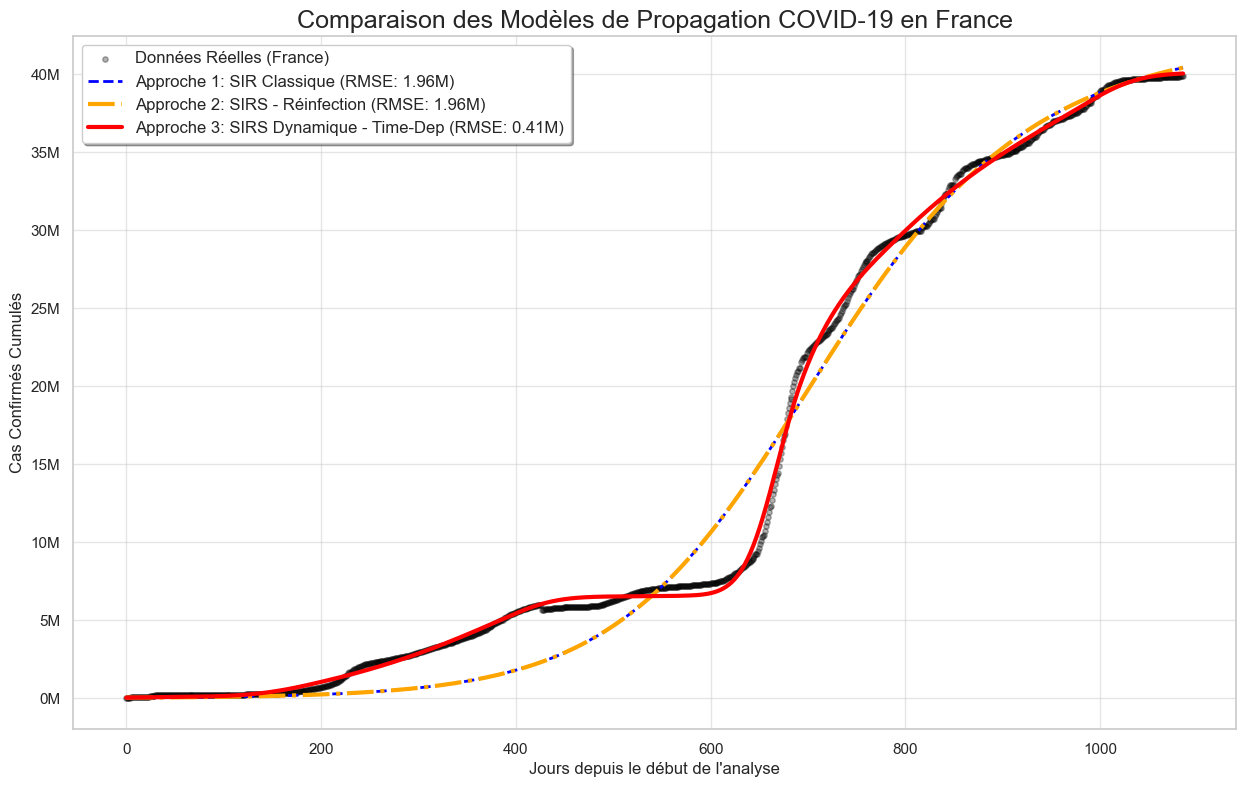

In [5]:
# Calcul des erreurs (RMSE - en millions)
rmse_sir = np.sqrt(mean_squared_error(y_real, y_pred_sir)) / 1e6
rmse_sirs = np.sqrt(mean_squared_error(y_real, y_pred_sirs)) / 1e6
rmse_dyn = np.sqrt(mean_squared_error(y_real, y_pred_dyn)) / 1e6

plt.figure(figsize=(15, 9))

# Données Réelles
plt.scatter(x_days, y_real, color='black', alpha=0.3, s=15, label='Données Réelles (France)')

# Modèle 1
plt.plot(x_days, y_pred_sir, color='blue', linestyle='--', linewidth=2, 
         label=f'Approche 1: SIR Classique (RMSE: {rmse_sir:.2f}M)')

# Modèle 2
plt.plot(x_days, y_pred_sirs, color='orange', linestyle='-.', linewidth=3, 
         label=f'Approche 2: SIRS - Réinfection (RMSE: {rmse_sirs:.2f}M)')

# Modèle 3
plt.plot(x_days, y_pred_dyn, color='red', linestyle='-', linewidth=3, 
         label=f'Approche 3: SIRS Dynamique - Time-Dep (RMSE: {rmse_dyn:.2f}M)')

plt.title('Comparaison des Modèles de Propagation COVID-19 en France', fontsize=18)
plt.xlabel('Jours depuis le début de l\'analyse', fontsize=12)
plt.ylabel('Cas Confirmés Cumulés', fontsize=12)
plt.legend(fontsize=12, loc='upper left', frameon=True, shadow=True)
plt.grid(True, alpha=0.5)

# Formatage de l'axe Y en Millions
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:.0f}M".format(x/1e6)))

plt.show()

In [ ]:
# --- ANÁLISE DO BETA (CORRIGIDA) ---

# Récupération des betas optimisés
betas_found = popt_dyn[2:]
beta_curve = [get_beta_t(t, betas_found) for t in x_days]

plt.figure(figsize=(14, 5))

# CORREÇÃO AQUI: Adicionado o 'r' antes das aspas em label=r'...'
plt.plot(x_days, beta_curve, color='purple', linewidth=2, label=r'Taux de Transmission ($\beta$) estimé')
plt.fill_between(x_days, beta_curve, color='purple', alpha=0.1)

plt.title(r'Évolution du Taux de Transmission en France (Modèle Dynamique)', fontsize=16)
plt.xlabel('Jours', fontsize=12)
plt.ylabel('Beta (Taux de contact)', fontsize=12)
plt.grid(True)
plt.legend()

plt.show()

print("--- CONCLUSION ---")
print("Le modèle SIR Classique sature trop vite (suppose une immunité totale).")
print("Le modèle SIRS corrige la tendance à long terme mais manque les vagues.")
print("Le modèle Dynamique capture les vagues successives (variants/politiques).")

ValueError: 
Taux de Transmission ($eta$) estimé
                      ^
ParseException: Expected end of text, found '$'  (at char 22), (line:1, col:23)

<Figure size 1400x500 with 1 Axes>

--- CONCLUSION ---
Le modèle SIR Classique sature trop vite (suppose une immunité totale).
Le modèle SIRS corrige la tendance à long terme mais manque les vagues.
Le modèle Dynamique capture les vagues successives (variants/politiques).
